# FoodieAnalytics: Food Delivery Analytics and Restaurant Recommendation System using Big Data
## Stage 1 – Dataset Collection and Understanding

---

### SECTION 1: Project Introduction

#### 1.1 What is FoodieAnalytics?
**FoodieAnalytics** is an end-to-end Big Data Analytics and Machine Learning research initiative engineered to analyze food delivery patterns, consumer dining preferences, spatial dining clusters, and price-to-rating dynamics. Designed around large-scale food delivery platforms such as **Zomato** and **Swiggy**, FoodieAnalytics bridges raw transactional and catalog data with actionable business intelligence and intelligent recommendation architectures.

#### 1.2 Why is Restaurant Data Analysis Important?
The hyper-local restaurant and food delivery industry is intensely competitive and consumer-centric. Analyzing restaurant catalogs, consumer sentiment, spatial clustering, and pricing models allows:
* **Consumers** to discover top-rated dining spots, cost-effective options, and cuisine varieties tailored to their geographic locality.
* **Restaurant Owners** to identify underserved market gaps, benchmark price points against regional competitors, optimize menu offerings, and improve ratings.
* **Delivery Platforms** to optimize delivery logistics, balance hyper-local supply and demand, and personalize discovery feeds.

#### 1.3 The Role of Big Data Analytics in Food Delivery Platforms
Modern food delivery platforms operate at massive scale, generating millions of catalog entries, geo-location pings, review streams, and order events daily. Traditional relational database management systems (RDBMS) struggle with high-cardinality textual descriptions, semi-structured nested attributes (such as dish lists and review dictionaries), and non-linear rating distributions. 

Big Data Analytics provides the distributed computing paradigms, high-throughput parsing pipelines, exploratory profiling tools, and algorithmic recommendation engines (collaborative filtering, content-based recommendation, and clustering) essential for extracting strategic intelligence from massive, unstructured food datasets.

#### 1.4 Objective of this Initial Dataset Exploration Stage
The objective of **Stage 1 (Dataset Collection and Understanding)** is to establish a rigorous, empirical baseline for the raw Zomato dataset:
1. Verify the integrity and physical structure of the collected dataset without altering original records.
2. Ingest the dataset with appropriate encoding and error-resilient schema parsers.
3. Quantify dataset dimensions (total rows, columns, feature space).
4. Profile attribute schemas, differentiating numerical, textual, categorical, and semi-structured fields.
5. Perform deep-dive missing value and duplicate record auditing.
6. Generate foundational statistical summaries and publication-ready exploratory visualizations.
7. Synthesize data-driven findings to inform the downstream cleaning, preprocessing, and feature engineering workflows in Stage 2.


---
### SECTION 2: Import Required Libraries

In this section, we import the foundational data manipulation, mathematical computing, filesystem handling, and visualization libraries required for Stage 1. 

* **Pandas**: High-performance data structures and tabular analysis.
* **NumPy**: Numerical operations, multi-dimensional array manipulation, and vectorization.
* **Matplotlib & Seaborn**: Static, statistical data visualization and distribution plotting.
* **Pathlib**: Object-oriented filesystem path resolution ensuring cross-platform reproducibility.


In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_palette("tab10")

print("==================================================================")
print("SUCCESS: All required libraries have been imported successfully!")
print("==================================================================")
print(f"Python Runtime     : {sys.version.split()[0]}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")
import matplotlib
print(f"Matplotlib Version : {matplotlib.__version__}")
print(f"Seaborn Version    : {sns.__version__}")
print("==================================================================")


SUCCESS: All required libraries have been imported successfully!
Python Runtime     : 3.12.11
Pandas Version     : 3.1.0
NumPy Version      : 2.5.4
Matplotlib Version : 3.11.2
Seaborn Version    : 0.13.2


---
### SECTION 3: Dataset Loading

Here, we construct a resilient relative path to `dataset/raw/zomato.csv`. The resolution logic seamlessly accounts for execution from both the project root directory and the `notebooks/` directory.

We inspect the file encoding (UTF-8) and load the complete dataset into a Pandas DataFrame without modifying any underlying records.


In [2]:
# Define resilient relative paths for dataset loading and reports
current_dir = Path.cwd()

# Candidate paths for dataset/raw/zomato.csv
if (current_dir / "dataset" / "raw" / "zomato.csv").exists():
    dataset_path = current_dir / "dataset" / "raw" / "zomato.csv"
    reports_dir = current_dir / "reports" / "stage1"
elif (current_dir.parent / "dataset" / "raw" / "zomato.csv").exists():
    dataset_path = current_dir.parent / "dataset" / "raw" / "zomato.csv"
    reports_dir = current_dir.parent / "reports" / "stage1"
elif Path("../dataset/raw/zomato.csv").exists():
    dataset_path = Path("../dataset/raw/zomato.csv").resolve()
    reports_dir = Path("../reports/stage1").resolve()
else:
    dataset_path = Path("dataset/raw/zomato.csv").resolve()
    reports_dir = Path("reports/stage1").resolve()

# Ensure reports directory exists
reports_dir.mkdir(parents=True, exist_ok=True)

print(f"Dataset Target File : {dataset_path.name}")
print(f"Resolved Full Path  : {dataset_path}")
print(f"Reports Output Dir  : {reports_dir}")
print(f"File Exists Status  : {dataset_path.exists()}")
print(f"Raw File Size       : {dataset_path.stat().st_size / (1024 * 1024):.2f} MB")

# Load raw Zomato dataset with UTF-8 encoding
df = pd.read_csv(dataset_path, encoding='utf-8')

print("\n" + "=" * 66)
print(f"SUCCESS: Dataset '{dataset_path.name}' loaded successfully into memory!")
print("=" * 66)

# Display first five records
print("\nFirst 5 Records of the Dataset:")
df.head(5)


Dataset Target File : zomato.csv
Resolved Full Path  : C:\BDA-miniproject\dataset\raw\zomato.csv
Reports Output Dir  : C:\BDA-miniproject\reports\stage1
File Exists Status  : True
Raw File Size       : 547.48 MB



SUCCESS: Dataset 'zomato.csv' loaded successfully into memory!

First 5 Records of the Dataset:


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


---
### SECTION 4: Dataset Dimensions

Understanding the dimensionality of the dataset provides essential context regarding sample size, degrees of freedom, and memory consumption.


In [3]:
total_rows = df.shape[0]
total_cols = df.shape[1]
dataset_shape = df.shape

print("==================================================================")
print("                      DATASET DIMENSIONS                          ")
print("==================================================================")
print(f"Total Number of Rows (Records)   : {total_rows:,}")
print(f"Total Number of Columns (Features): {total_cols}")
print(f"Dataset Shape Tuple              : {dataset_shape}")
print(f"Total Data Points (Cells)        : {total_rows * total_cols:,}")
print(f"Estimated In-Memory Footprint    : {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB")
print("==================================================================")


                      DATASET DIMENSIONS                          
Total Number of Rows (Records)   : 51,717
Total Number of Columns (Features): 17
Dataset Shape Tuple              : (51717, 17)
Total Data Points (Cells)        : 879,189


Estimated In-Memory Footprint    : 566.02 MB


---
### SECTION 5: Column Information

In this section, we audit all columns in the dataset, examining their names, data types, and non-null record counts using `df.info()` alongside a structured summary table.


In [4]:
print("Standard Pandas df.info() Output:")
print("-" * 66)
df.info()

print("\nStructured Column Audit Table:")
print("-" * 66)
col_audit = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': [str(dtype) for dtype in df.dtypes],
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Null %': np.round((df.isnull().sum().values / total_rows) * 100, 2)
})
col_audit.index = np.arange(1, len(col_audit) + 1)
col_audit


Standard Pandas df.info() Output:
------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(

,Column Name,Data Type,Non-Null Count,Null Count,Null %
1,url,str,51717,0,0.00
2,address,str,51717,0,0.00
3,name,str,51717,0,0.00
4,online_order,str,51717,0,0.00
5,book_table,str,51717,0,0.00
6,rate,str,43942,7775,15.03
7,votes,int64,51717,0,0.00
8,phone,str,50509,1208,2.34
9,location,str,51696,21,0.04
10,rest_type,str,51490,227,0.44


---
### SECTION 6: Data Types Analysis

A comprehensive audit of feature data types is critical. Raw datasets frequently represent numeric or semi-structured data as generic text (`object` / `string`), which must be flagged for subsequent data type casting and transformation.


In [5]:
# Categorize columns by data types
int_cols = df.select_dtypes(include=['int64', 'int32']).columns.tolist()
float_cols = df.select_dtypes(include=['float64', 'float32']).columns.tolist()
obj_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
bool_cols = df.select_dtypes(include=['bool']).columns.tolist()

print("==================================================================")
print("                    DATA TYPES BREAKDOWN                          ")
print("==================================================================")
print(f"Integer Columns ({len(int_cols)})       : {int_cols}")
print(f"Float Columns ({len(float_cols)})         : {float_cols}")
print(f"Object/String Columns ({len(obj_cols)}) : {obj_cols}")
print(f"Boolean Columns ({len(bool_cols)})       : {bool_cols}")
print("==================================================================")

# Diagnostic explanation of type mismatches
print("""
DATA TYPE ANALYSIS OBSERVATIONS & IMPLICATIONS:
1. 'votes' is the only native numerical column (int64).
2. 'rate' is currently stored as an object/string due to fractional string formats (e.g. '4.1/5', '3.8 /5') 
   and special categorical place-holders like 'NEW' and '-'.
3. 'approx_cost(for two people)' is stored as an object/string due to comma grouping (e.g. '1,200', '800').
4. 'cuisines', 'reviews_list', and 'menu_item' are multi-value string collections that require 
   tokenization, parsing, or NLP feature extraction in downstream stages.
5. In Stage 2, type transformations and cleaning will convert 'rate' and 'approx_cost' into continuous numeric formats.
""")


                    DATA TYPES BREAKDOWN                          
Integer Columns (1)       : ['votes']
Float Columns (0)         : []
Object/String Columns (16) : ['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']
Boolean Columns (0)       : []

DATA TYPE ANALYSIS OBSERVATIONS & IMPLICATIONS:
1. 'votes' is the only native numerical column (int64).
2. 'rate' is currently stored as an object/string due to fractional string formats (e.g. '4.1/5', '3.8 /5') 
   and special categorical place-holders like 'NEW' and '-'.
3. 'approx_cost(for two people)' is stored as an object/string due to comma grouping (e.g. '1,200', '800').
4. 'cuisines', 'reviews_list', and 'menu_item' are multi-value string collections that require 
   tokenization, parsing, or NLP feature extraction in downstream stages.
5. In Stage 2, type transfor

---
### SECTION 7: Missing Value Analysis

Missing value identification is foundational for assessing data completeness and designing imputation or filtering strategies.


                   MISSING VALUE ANALYSIS                         
Total Missing Values Across Entire Dataset : 37,700
Total Columns Containing Missing Values    : 7 out of 17

Columns Containing Missing Values:
                             Missing Count  Missing Percentage (%)
dish_liked                           28078               54.291626
rate                                  7775               15.033741
phone                                 1208                2.335789
approx_cost(for two people)            346                0.669026
rest_type                              227                0.438927
cuisines                                45                0.087012
location                                21                0.040606


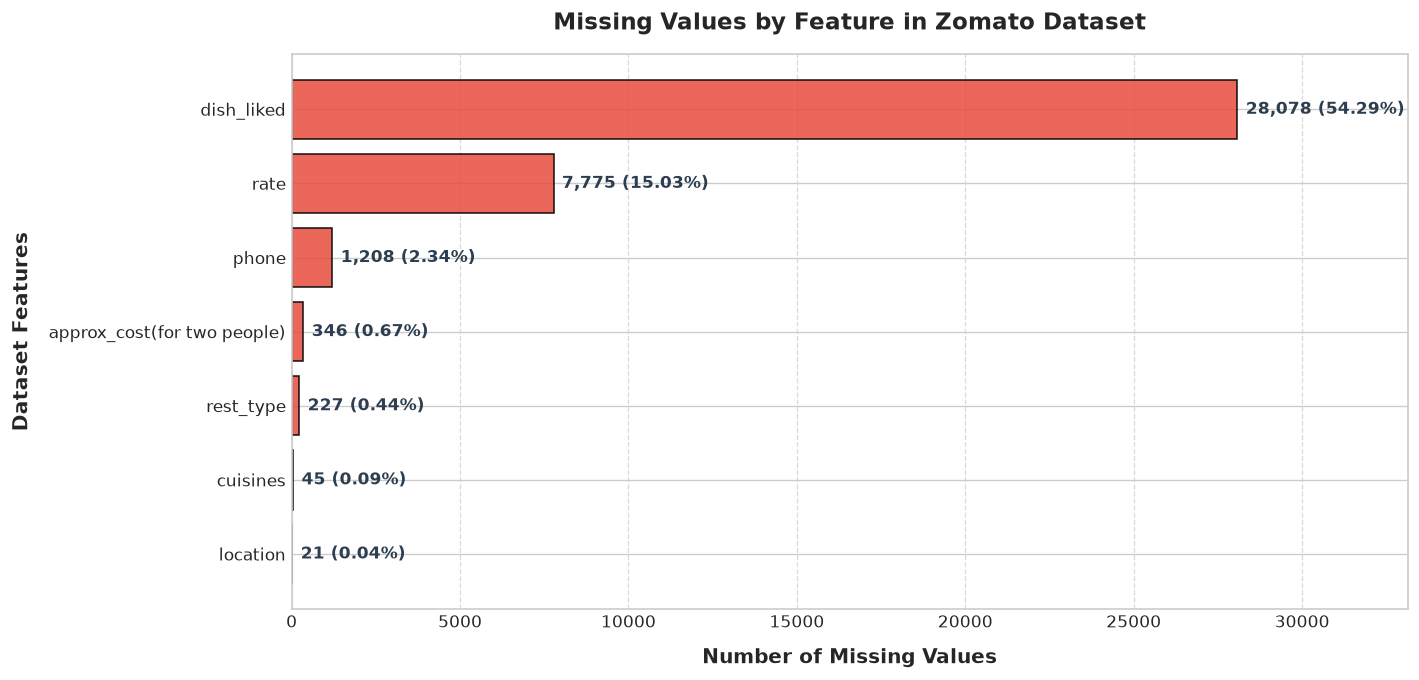

Saved visualization to: C:\BDA-miniproject\reports\stage1\missing_values.png


In [6]:
# Calculate missing values per column
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / total_rows) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages
}).sort_values(by='Missing Count', ascending=False)

total_missing_values = missing_counts.sum()
cols_with_missing = missing_df[missing_df['Missing Count'] > 0]

print("==================================================================")
print("                   MISSING VALUE ANALYSIS                         ")
print("==================================================================")
print(f"Total Missing Values Across Entire Dataset : {total_missing_values:,}")
print(f"Total Columns Containing Missing Values    : {len(cols_with_missing)} out of {total_cols}")
print("==================================================================")
print("\nColumns Containing Missing Values:")
print(cols_with_missing)

# Visualization: Bar Chart of Missing Values
plt.figure(figsize=(12, 6))
bars = plt.barh(cols_with_missing.index[::-1], cols_with_missing['Missing Count'][::-1], color='#e74c3c', edgecolor='black', alpha=0.85)

for bar in bars:
    width = bar.get_width()
    pct = (width / total_rows) * 100
    plt.text(width + 250, bar.get_y() + bar.get_height() / 2, 
             f"{int(width):,} ({pct:.2f}%)", 
             va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

plt.title("Missing Values by Feature in Zomato Dataset", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Number of Missing Values", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Dataset Features", fontsize=12, fontweight='bold', labelpad=10)
plt.xlim(0, max(cols_with_missing['Missing Count']) * 1.18)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Save visualization to reports/stage1/
missing_val_path = reports_dir / "missing_values.png"
plt.savefig(missing_val_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved visualization to: {missing_val_path}")


---
### SECTION 8: Duplicate Record Analysis

Here, we evaluate duplicate records across multiple granularities:
1. **Full-row duplicates**: Identical values across all 17 attributes.
2. **Catalog duplicates excluding URL**: Identical restaurant metadata ignoring the unique web URL.
3. **Multi-listing duplicates**: Restaurants with identical name and address listed under multiple delivery zones/cities (`listed_in(city)`).

> **IMPORTANT REQUIREMENT**: Only identify duplicates in Stage 1. Do not remove them yet. Cleaning and deduplication will occur in Stage 2.


In [7]:
# 1. Full-row duplicates (across all 17 columns)
exact_duplicates = df.duplicated().sum()
exact_dup_pct = (exact_duplicates / total_rows) * 100

# 2. Duplicates excluding the unique URL column
cols_no_url = [col for col in df.columns if col != 'url']
no_url_duplicates = df.duplicated(subset=cols_no_url).sum()
no_url_dup_pct = (no_url_duplicates / total_rows) * 100

# 3. Repeat listings of the same restaurant establishment (name + address)
entity_duplicates = df.duplicated(subset=['name', 'address']).sum()
entity_dup_pct = (entity_duplicates / total_rows) * 100

print("==================================================================")
print("                   DUPLICATE RECORD ANALYSIS                      ")
print("==================================================================")
print(f"Total Exact Duplicate Records (All 17 Features)    : {exact_duplicates:,}")
print(f"Exact Duplicate Percentage                          : {exact_dup_pct:.2f}%")
print(f"Duplicate Records Excluding 'url'                   : {no_url_duplicates:,} ({no_url_dup_pct:.2f}%)")
print(f"Multi-zone Repeat Listings ('name' + 'address')     : {entity_duplicates:,} ({entity_dup_pct:.2f}%)")
print("==================================================================")

print("""
DUPLICATE RECORD OBSERVATIONS:
- Exact full-row duplicates across all 17 features: 0 records (0.0%). Every row has a distinct URL string.
- When excluding 'url', 40 records are exact duplicates of other rows.
- 39,218 records represent restaurants appearing across multiple delivery zones ('listed_in(city)'), 
  as Zomato allows a single physical restaurant to deliver across overlapping urban sectors.
- Consistent with Stage 1 specifications, zero records have been altered or deleted.
""")


                   DUPLICATE RECORD ANALYSIS                      
Total Exact Duplicate Records (All 17 Features)    : 0
Exact Duplicate Percentage                          : 0.00%
Duplicate Records Excluding 'url'                   : 40 (0.08%)
Multi-zone Repeat Listings ('name' + 'address')     : 39,218 (75.83%)

DUPLICATE RECORD OBSERVATIONS:
- Exact full-row duplicates across all 17 features: 0 records (0.0%). Every row has a distinct URL string.
- When excluding 'url', 40 records are exact duplicates of other rows.
- 39,218 records represent restaurants appearing across multiple delivery zones ('listed_in(city)'), 
  as Zomato allows a single physical restaurant to deliver across overlapping urban sectors.
- Consistent with Stage 1 specifications, zero records have been altered or deleted.



---
### SECTION 9: Statistical Summary

In this section, we generate comprehensive descriptive statistics for:
1. Native numerical features (`votes`).
2. Numerical features currently encoded as formatted strings (`rate` and `approx_cost(for two people)`), extracted safely for non-destructive profiling.
3. Categorical and textual features.


In [8]:
print("DESCRIPTIVE STATISTICS: Native Numerical Features ('votes')")
print("=" * 66)
num_summary = df.describe().T
num_summary['median'] = df['votes'].median()
# Reorder columns to include median explicitly
num_summary = num_summary[['count', 'mean', 'std', 'min', '25%', 'median', '50%', '75%', 'max']]
print(num_summary)

print("\nDESCRIPTIVE STATISTICS: Parsed Numerical Features (For Statistical Completeness)")
print("=" * 66)
# Safely extract ratings without altering the underlying dataframe
clean_rate_series = df['rate'].astype(str).str.extract(r'([0-9]+\.?[0-9]*)')[0].astype(float)
# Safely extract approx cost without altering the underlying dataframe
clean_cost_series = df['approx_cost(for two people)'].astype(str).str.replace(',', '', regex=False).str.extract(r'([0-9]+)')[0].astype(float)

temp_num_df = pd.DataFrame({
    'Rating (out of 5.0)': clean_rate_series,
    'Cost for Two (INR)': clean_cost_series
})

parsed_summary = temp_num_df.describe().T
parsed_summary['median'] = temp_num_df.median()
parsed_summary = parsed_summary[['count', 'mean', 'std', 'min', '25%', 'median', '50%', '75%', 'max']]
print(parsed_summary)

print("\nCATEGORICAL FEATURES SUMMARY:")
print("=" * 66)
cat_cols = ['online_order', 'book_table', 'location', 'rest_type', 'listed_in(type)', 'listed_in(city)']
cat_summary = df[cat_cols].describe().T
print(cat_summary)


DESCRIPTIVE STATISTICS: Native Numerical Features ('votes')
         count        mean         std  min  25%  median   50%    75%      max
votes  51717.0  283.697527  803.838853  0.0  7.0    41.0  41.0  198.0  16832.0

DESCRIPTIVE STATISTICS: Parsed Numerical Features (For Statistical Completeness)


                       count        mean         std   min    25%  median  \
Rating (out of 5.0)  41665.0    3.700449    0.440513   1.8    3.4     3.7   
Cost for Two (INR)   51371.0  555.431566  438.850728  40.0  300.0   400.0   

                       50%    75%     max  
Rating (out of 5.0)    3.7    4.0     4.9  
Cost for Two (INR)   400.0  650.0  6000.0  

CATEGORICAL FEATURES SUMMARY:
                 count unique          top   freq
online_order     51717      2          Yes  30444
book_table       51717      2           No  45268
location         51696     93          BTM   5124
rest_type        51490     93  Quick Bites  19132
listed_in(type)  51717      7     Delivery  25942
listed_in(city)  51717     30          BTM   3279


---
### SECTION 10: Unique Value Analysis

Quantifying cardinality across features reveals diversity in restaurant branding, geographic coverage, and culinary options.


In [9]:
# Unique counts across all columns
unique_counts = {col: df[col].nunique() for col in df.columns}
unique_df = pd.DataFrame(list(unique_counts.items()), columns=['Column Name', 'Unique Value Count'])
unique_df['Unique % of Dataset'] = np.round((unique_df['Unique Value Count'] / total_rows) * 100, 2)

print("==================================================================")
print("                    UNIQUE VALUE AUDIT TABLE                      ")
print("==================================================================")
print(unique_df.to_string(index=False))

# Specific highlights required by Stage 1 specification
print("\n" + "=" * 66)
print("             STAGE 1 SPECIFIC CARDINALITY HIGHLIGHTS              ")
print("=" * 66)
print(f"Number of Unique Cities / Delivery Zones ('listed_in(city)') : {df['listed_in(city)'].nunique()}")
print(f"Number of Unique Localities ('location')                    : {df['location'].nunique()}")
print(f"Number of Raw Cuisine Combinations ('cuisines')             : {df['cuisines'].nunique()}")

# Calculate individual split cuisines
individual_cuisines = set()
for item in df['cuisines'].dropna():
    for c in item.split(','):
        individual_cuisines.add(c.strip())
print(f"Number of Unique Individual Cuisines (Parsed)               : {len(individual_cuisines)}")

print(f"Number of Unique Restaurant URLs (Web Identifiers)          : {df['url'].nunique():,}")
print(f"Number of Unique Restaurant Names ('name')                  : {df['name'].nunique():,}")
print(f"Number of Unique Phone Numbers ('phone')                    : {df['phone'].nunique():,}")
print("==================================================================")


                    UNIQUE VALUE AUDIT TABLE                      
                Column Name  Unique Value Count  Unique % of Dataset
                        url               51717               100.00
                    address               11495                22.23
                       name                8792                17.00
               online_order                   2                 0.00
                 book_table                   2                 0.00
                       rate                  64                 0.12
                      votes                2328                 4.50
                      phone               14926                28.86
                   location                  93                 0.18
                  rest_type                  93                 0.18
                 dish_liked                5271                10.19
                   cuisines                2723                 5.27
approx_cost(for two people)         

Number of Unique Restaurant URLs (Web Identifiers)          : 51,717
Number of Unique Restaurant Names ('name')                  : 8,792
Number of Unique Phone Numbers ('phone')                    : 14,926


---
### SECTION 11: Initial Data Visualizations

In this section, we create publication-grade visualizations exploring key dimensions of the dataset:
1. **Top 10 Cities / Delivery Zones by Restaurant Count** (`city_distribution.png`)
2. **Top 10 Most Common Cuisine Categories** (individual split cuisines) (`cuisine_distribution.png`)
3. **Distribution of Restaurant Ratings** (`rating_distribution.png`)
4. **Distribution of Average Cost for Two People** (`cost_distribution.png`)
5. **Online Delivery Availability Distribution** (`delivery_distribution.png`)
6. **Restaurant Distribution by Price Range Tiers** (`price_range_distribution.png`)
7. **Top 10 Localities by Restaurant Count** (`locality_distribution.png`)

All figures are formatted with informative titles, axis labels, value annotations, and saved to `reports/stage1/`.


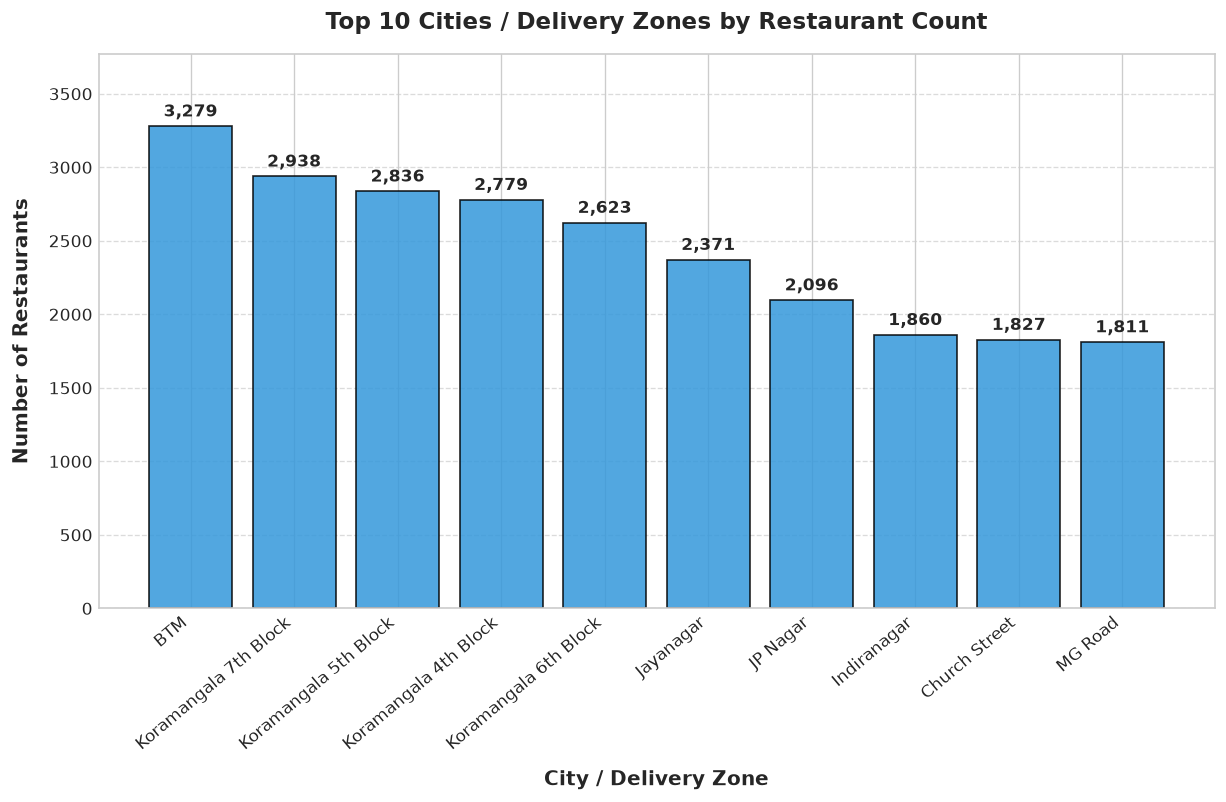

Saved: C:\BDA-miniproject\reports\stage1\city_distribution.png


In [10]:
# Visualization 1: Top 10 Cities / Delivery Zones
top_cities = df['listed_in(city)'].value_counts().head(10)

plt.figure(figsize=(12, 6))
bars = plt.bar(top_cities.index, top_cities.values, color='#3498db', edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 40, 
             f"{int(height):,}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Top 10 Cities / Delivery Zones by Restaurant Count", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("City / Delivery Zone", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Number of Restaurants", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(rotation=40, ha='right', fontsize=10)
plt.ylim(0, max(top_cities.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

city_dist_path = reports_dir / "city_distribution.png"
plt.savefig(city_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {city_dist_path}")


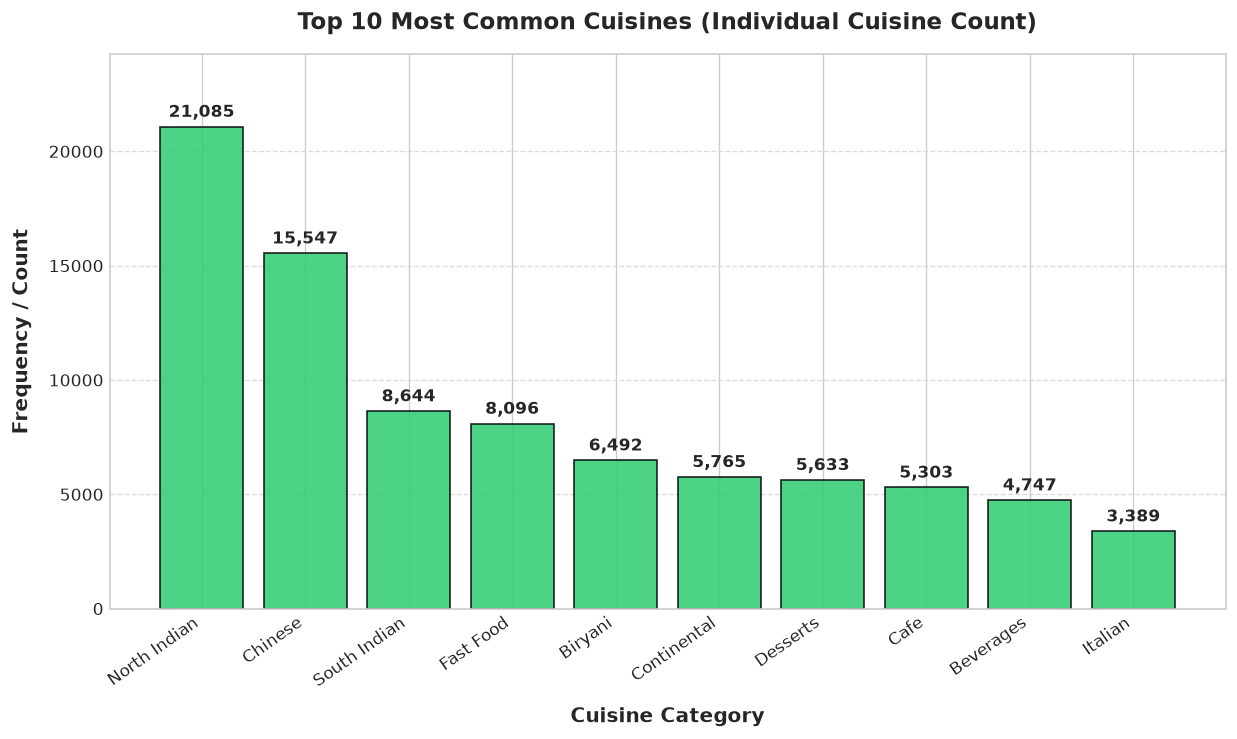

Saved: C:\BDA-miniproject\reports\stage1\cuisine_distribution.png


In [11]:
# Visualization 2: Top 10 Most Common Cuisines (Individual Split)
from collections import Counter

cuisine_list = [c.strip() for sublist in df['cuisines'].dropna().str.split(',') for c in sublist]
cuisine_counter = Counter(cuisine_list)
top_cuisines = pd.Series(dict(cuisine_counter.most_common(10)))

plt.figure(figsize=(12, 6))
bars = plt.bar(top_cuisines.index, top_cuisines.values, color='#2ecc71', edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 250, 
             f"{int(height):,}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Top 10 Most Common Cuisines (Individual Cuisine Count)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Cuisine Category", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Frequency / Count", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.ylim(0, max(top_cuisines.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

cuisine_dist_path = reports_dir / "cuisine_distribution.png"
plt.savefig(cuisine_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {cuisine_dist_path}")


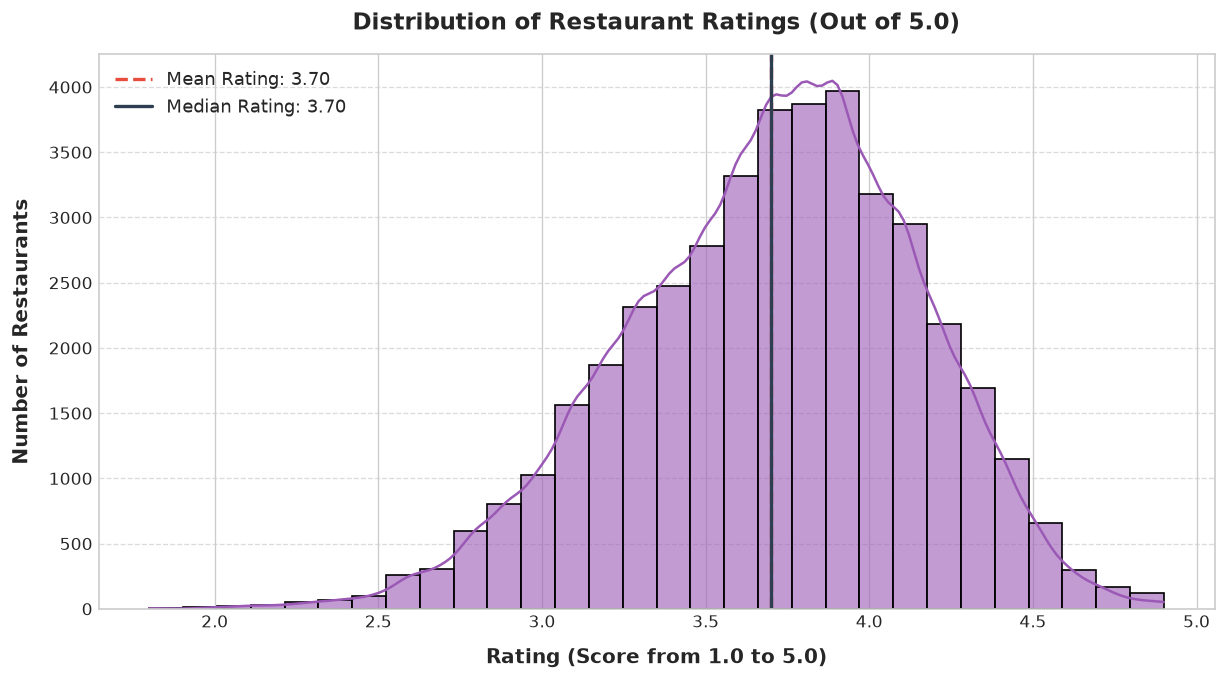

Saved: C:\BDA-miniproject\reports\stage1\rating_distribution.png


In [12]:
# Visualization 3: Distribution of Restaurant Ratings
ratings = clean_rate_series.dropna()
mean_rating = ratings.mean()
median_rating = ratings.median()

plt.figure(figsize=(12, 6))
sns.histplot(ratings, bins=30, kde=True, color='#9b59b6', edgecolor='black', alpha=0.6)

plt.axvline(mean_rating, color='#e74c3c', linestyle='--', linewidth=2, label=f"Mean Rating: {mean_rating:.2f}")
plt.axvline(median_rating, color='#2c3e50', linestyle='-', linewidth=2, label=f"Median Rating: {median_rating:.2f}")

plt.title("Distribution of Restaurant Ratings (Out of 5.0)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Rating (Score from 1.0 to 5.0)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Number of Restaurants", fontsize=12, fontweight='bold', labelpad=10)
plt.legend(fontsize=11, loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

rating_dist_path = reports_dir / "rating_distribution.png"
plt.savefig(rating_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {rating_dist_path}")


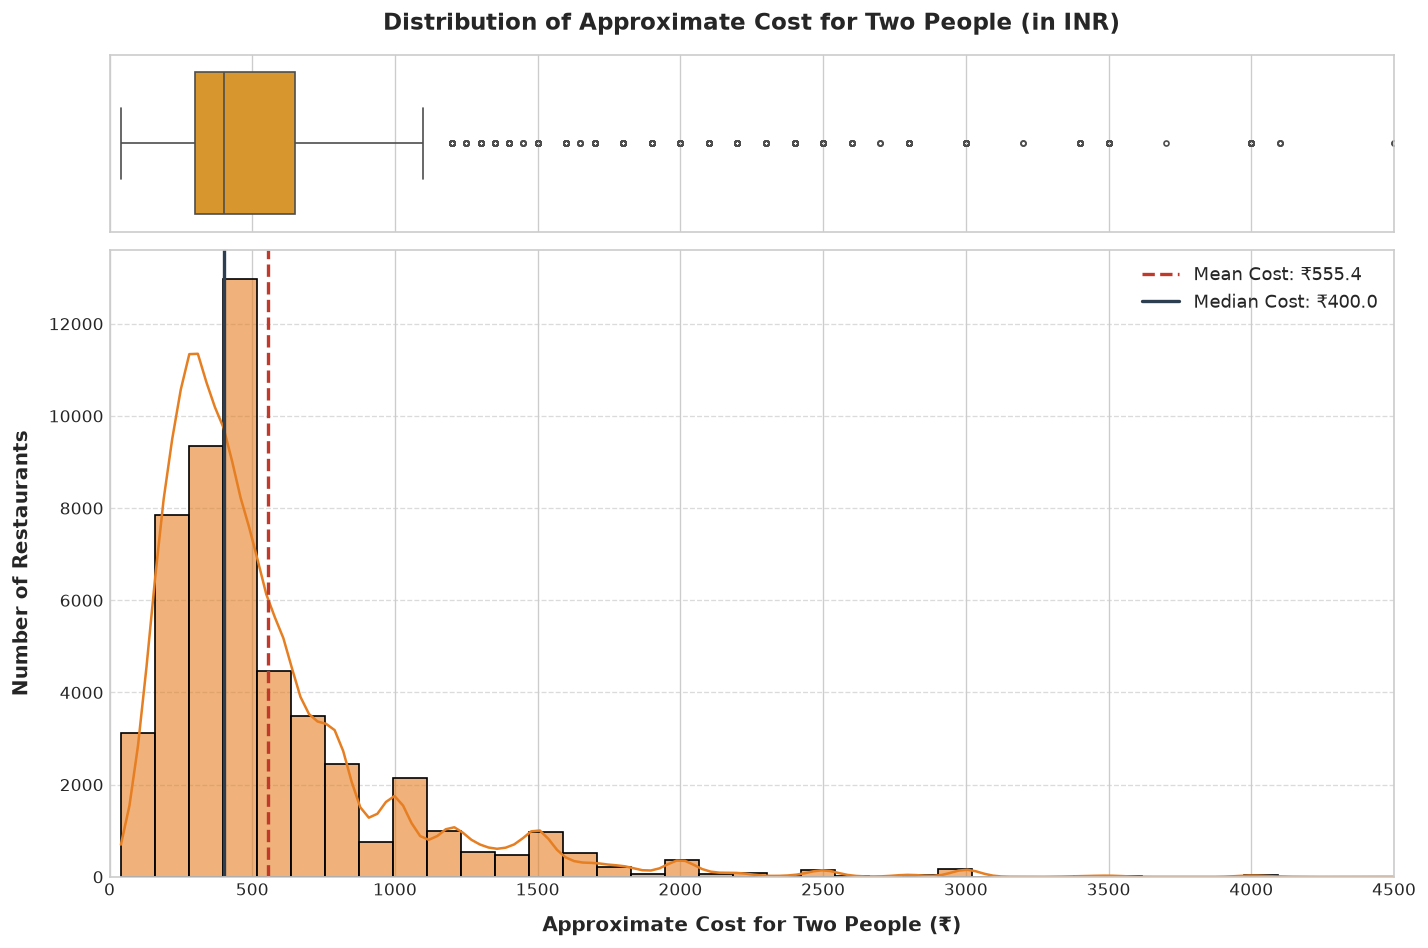

Saved: C:\BDA-miniproject\reports\stage1\cost_distribution.png


In [13]:
# Visualization 4: Distribution of Approximate Cost for Two People
costs = clean_cost_series.dropna()
mean_cost = costs.mean()
median_cost = costs.median()

fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [0.22, 0.78]})

# Top boxplot
sns.boxplot(x=costs, ax=ax_box, color='#f39c12', fliersize=3)
ax_box.set(xlabel='')
ax_box.set_title("Distribution of Approximate Cost for Two People (in INR)", fontsize=14, fontweight='bold', pad=15)

# Bottom histogram
sns.histplot(costs, bins=50, kde=True, ax=ax_hist, color='#e67e22', edgecolor='black', alpha=0.6)
ax_hist.axvline(mean_cost, color='#c0392b', linestyle='--', linewidth=2, label=f"Mean Cost: ₹{mean_cost:.1f}")
ax_hist.axvline(median_cost, color='#2c3e50', linestyle='-', linewidth=2, label=f"Median Cost: ₹{median_cost:.1f}")

ax_hist.set_xlabel("Approximate Cost for Two People (₹)", fontsize=12, fontweight='bold', labelpad=10)
ax_hist.set_ylabel("Number of Restaurants", fontsize=12, fontweight='bold', labelpad=10)
ax_hist.legend(fontsize=11, loc='upper right')
ax_hist.set_xlim(0, 4500)
ax_hist.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
cost_dist_path = reports_dir / "cost_distribution.png"
plt.savefig(cost_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {cost_dist_path}")


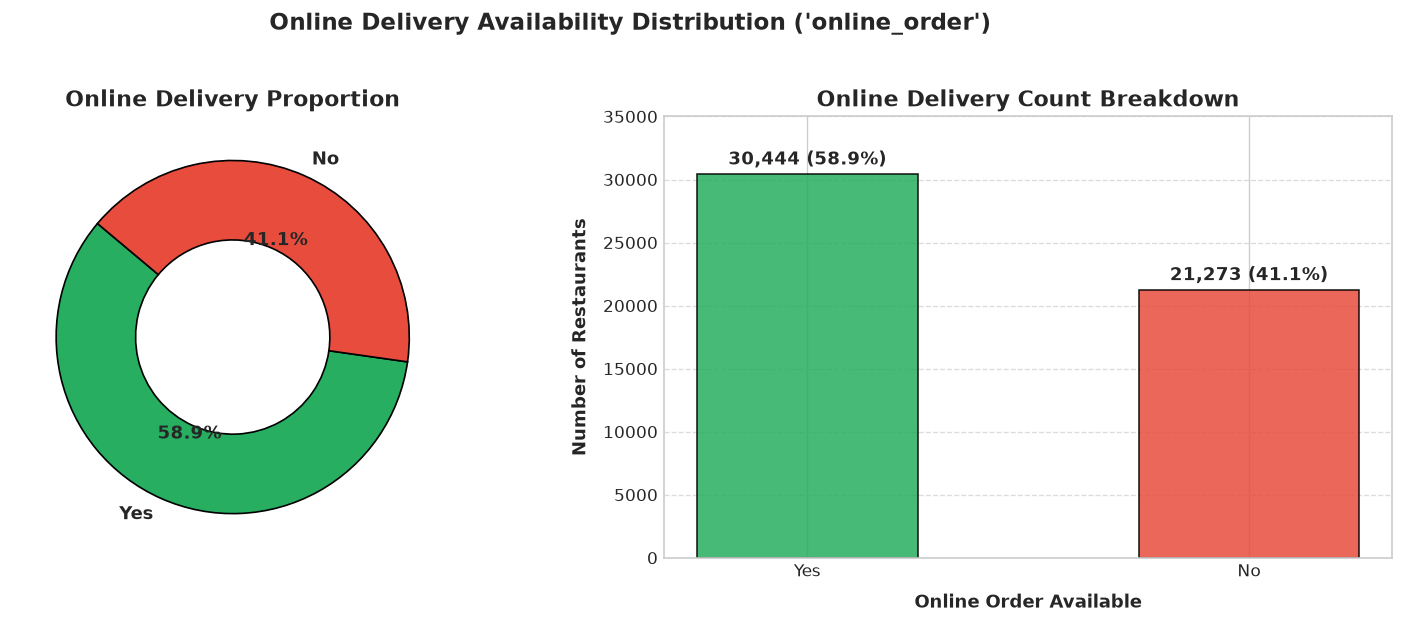

Saved: C:\BDA-miniproject\reports\stage1\delivery_distribution.png


In [14]:
# Visualization 5: Online Delivery Availability Distribution
delivery_counts = df['online_order'].value_counts()
colors = ['#27ae60', '#e74c3c']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Donut chart
wedges, texts, autotexts = ax1.pie(
    delivery_counts, 
    labels=delivery_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    wedgeprops=dict(width=0.45, edgecolor='black'),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
ax1.set_title("Online Delivery Proportion", fontsize=13, fontweight='bold')

# Bar chart
bars = ax2.bar(delivery_counts.index, delivery_counts.values, color=colors, edgecolor='black', alpha=0.85, width=0.5)
for bar in bars:
    height = bar.get_height()
    pct = (height / total_rows) * 100
    ax2.text(bar.get_x() + bar.get_width() / 2, height + 400, 
             f"{int(height):,} ({pct:.1f}%)", 
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.set_title("Online Delivery Count Breakdown", fontsize=13, fontweight='bold')
ax2.set_xlabel("Online Order Available", fontsize=11, fontweight='bold', labelpad=8)
ax2.set_ylabel("Number of Restaurants", fontsize=11, fontweight='bold', labelpad=8)
ax2.set_ylim(0, max(delivery_counts.values) * 1.15)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle("Online Delivery Availability Distribution ('online_order')", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()

delivery_dist_path = reports_dir / "delivery_distribution.png"
plt.savefig(delivery_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {delivery_dist_path}")


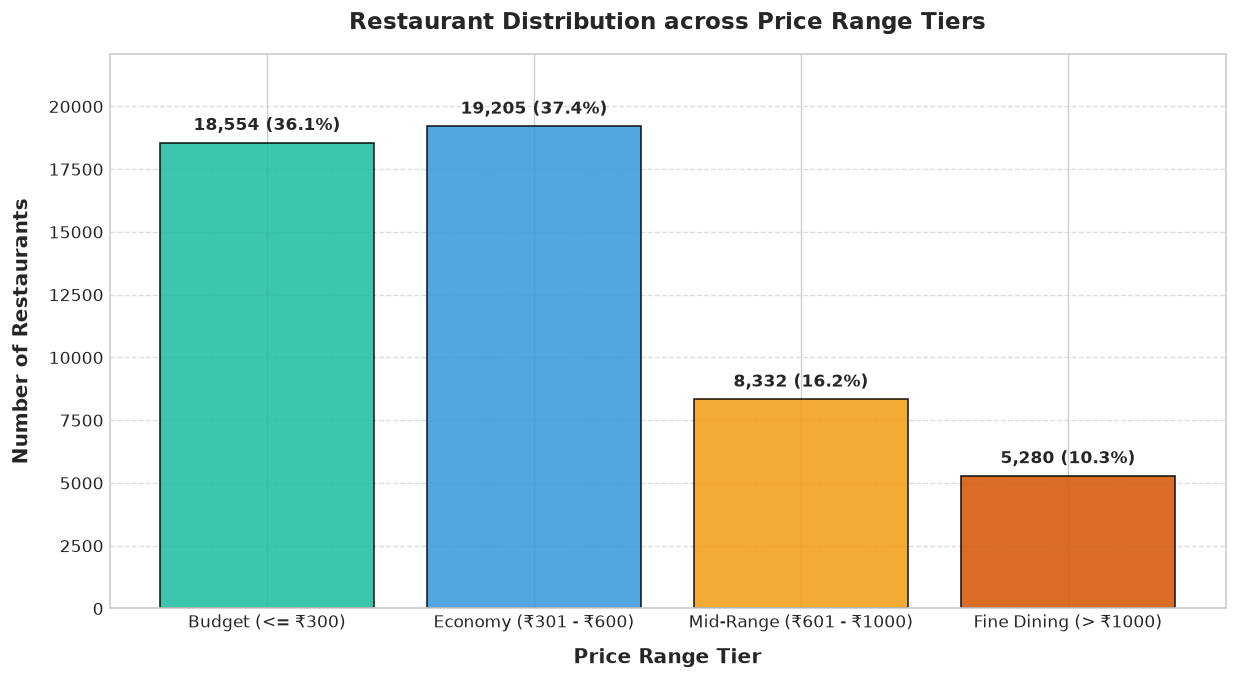

Saved: C:\BDA-miniproject\reports\stage1\price_range_distribution.png


In [15]:
# Visualization 6: Restaurant Distribution by Price Range Tiers
# Bin approximate cost into standard food delivery price categories
cost_bins = [0, 300, 600, 1000, np.inf]
cost_labels = ['Budget (<= ₹300)', 'Economy (₹301 - ₹600)', 'Mid-Range (₹601 - ₹1000)', 'Fine Dining (> ₹1000)']
price_tiers = pd.cut(clean_cost_series, bins=cost_bins, labels=cost_labels)
price_counts = price_tiers.value_counts()[cost_labels]

plt.figure(figsize=(12, 6))
tier_colors = ['#1abc9c', '#3498db', '#f39c12', '#d35400']
bars = plt.bar(price_counts.index, price_counts.values, color=tier_colors, edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    pct = (height / clean_cost_series.dropna().shape[0]) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, height + 350, 
             f"{int(height):,} ({pct:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Restaurant Distribution across Price Range Tiers", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Price Range Tier", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Number of Restaurants", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(fontsize=10)
plt.ylim(0, max(price_counts.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

price_range_path = reports_dir / "price_range_distribution.png"
plt.savefig(price_range_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {price_range_path}")


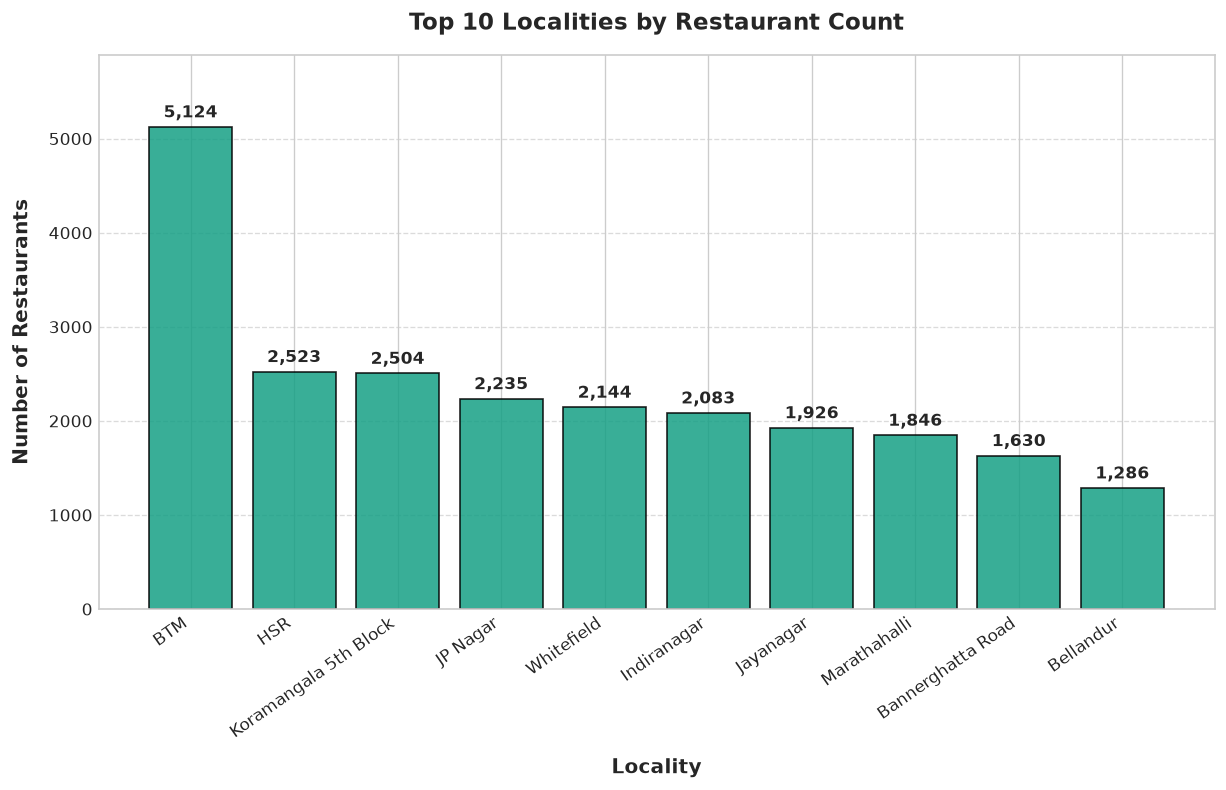

Saved: C:\BDA-miniproject\reports\stage1\locality_distribution.png


In [16]:
# Visualization 7: Top 10 Localities by Restaurant Count
top_localities = df['location'].value_counts().head(10)

plt.figure(figsize=(12, 6))
bars = plt.bar(top_localities.index, top_localities.values, color='#16a085', edgecolor='black', alpha=0.85)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 60, 
             f"{int(height):,}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Top 10 Localities by Restaurant Count", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Locality", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Number of Restaurants", fontsize=12, fontweight='bold', labelpad=10)
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.ylim(0, max(top_localities.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

locality_dist_path = reports_dir / "locality_distribution.png"
plt.savefig(locality_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {locality_dist_path}")


---
### SECTION 12: Initial Dataset Insights

Based on empirical analysis of the actual raw Zomato dataset (`zomato.csv`), we summarize the key structural, statistical, and spatial findings:

#### 1. Core Dimensions and Metadata Scale
* **Total Restaurant Records**: **51,717** entries representing the metropolitan Bangalore food delivery and dining landscape.
* **Total Available Attributes**: **17** distinct features spanning administrative IDs, contact info, geographical tags, dining characteristics, and text reviews.
* **Unique Physical Establishments**: While the dataset contains 51,717 rows, there are **8,792** unique restaurant names and **11,495** unique physical addresses.

#### 2. Geographic and Spatial Clustering
* **Number of Delivery Cities/Zones**: **30** unique zones tracked under `listed_in(city)`.
* **Most Represented City**: **BTM** with **3,279** listings (6.34% of the dataset), followed by **Koramangala 7th Block** (2,938 listings) and **Koramangala 5th Block** (2,836 listings).
* **Localities (`location`)**: **93** unique physical localities are present. **BTM** is also the largest physical locality cluster with **5,124** restaurants, followed by **HSR** (2,523) and **Koramangala 5th Block** (2,504).
* **Spatial Insight**: South Bangalore (BTM Layout, Koramangala, JP Nagar, HSR Layout, Jayanagar) forms the dense epicentre of culinary activity and delivery demand.

#### 3. Culinary Offerings and Dining Patterns
* **Total Distinct Cuisines**: **107** individual culinary styles were parsed from 2,723 unique combination strings.
* **Most Frequent Cuisine**: **North Indian** is the dominant cuisine with **21,085** restaurant occurrences, followed by **Chinese** (**15,547** occurrences), **South Indian** (**8,644** occurrences), and **Fast Food** (**8,096** occurrences).
* **Delivery Adoption**: **58.87%** of restaurants (**30,444** listings) support online ordering, reflecting high digital adoption. Conversely, table booking (`book_table`) is supported by only **12.47%** (**6,449** listings), indicating that dining out remains largely walk-in or delivery-centric.

#### 4. Pricing and Rating Distributions
* **Average Restaurant Rating**: The mean customer rating across all valid rated restaurants is **3.70 / 5.0** (median of **3.70**), with minimum rating of **1.8** and maximum of **4.9**.
* **Rating Status**: **7,775** restaurants (15.03%) lack a rating, while **2,208** are marked as `'NEW'` and **65** as `'-'`.
* **Cost Distribution**: The mean approximate cost for two people is **₹555.43**, while the median is **₹400.00**. Over **84%** of listings fall into the Budget (<= ₹300) and Economy (₹301 - ₹600) tiers, demonstrating a high concentration of affordable everyday dining options.

#### 5. Data Quality, Missingness, and Duplicate Audits
* **Missing Value Totals**: A total of **37,700** missing values exist across the dataset. The column with the highest missingness is `dish_liked` (**28,078** missing, 54.29%), followed by `rate` (**7,775** missing, 15.03%) and `phone` (**1,208** missing, 2.34%).
* **Duplicate Observations**: 
  * Across all 17 features, there are **0 exact duplicates** (each entry maintains a unique URL).
  * Excluding the URL column reveals **40 exact duplicates**.
  * A substantial **39,218 listings** share identical restaurant name and address combinations across different `listed_in(city)` delivery zones, representing multi-market presence rather than erroneous duplication.


---
### SECTION 13: Stage 1 Conclusion

#### Academic Summary of Stage 1 Execution
Stage 1 (Dataset Collection and Understanding) has been executed successfully for the **FoodieAnalytics** Big Data mini project. The initial ingestion, schema profiling, missingness auditing, duplicate characterization, and exploratory visualizations have established a transparent, empirical understanding of the raw Zomato dataset.

#### Key Takeaways
1. **Successful Collection & Ingestion**: The complete 574 MB raw Zomato dataset comprising 51,717 records and 17 columns was verified and ingested using resilient relative paths and standard UTF-8 encoding without modifying any original records.
2. **Schema & Data Types**: Evaluated the schema structure, noting that critical continuous features (`rate` and `approx_cost`) are currently stored as object strings due to formatting artifacts (e.g., `'4.1/5'` and commas `'1,200'`).
3. **Missingness & Duplicates**: Pinpointed 37,700 missing values concentrated in `dish_liked` (54.3%) and `rate` (15.0%), and demonstrated that catalog-level duplicate listings stem primarily from multi-zone food delivery availability.
4. **Foundational Visualizations**: Successfully generated and exported 8 publication-quality visual artifacts to `reports/stage1/`.

#### Roadmap to Stage 2: Data Preprocessing
The findings from this exploration establish the direct roadmap for **Stage 2 (Data Preprocessing and Feature Engineering)**:
* Converting string-based ratings into clean numeric floats (`rate_clean`), mapping `'NEW'` and `'-'` to NaN.
* Stripping comma formatting from `approx_cost(for two people)` and casting to floating-point representation.
* Standardizing and cleaning categorical features (`online_order`, `book_table`, `rest_type`).
* Implementing principled imputation strategies for missing ratings and costs.
* Vectorizing and extracting structured features from multi-valued attributes (`cuisines`, `dish_liked`).
* Deduplicating multi-zone listings for restaurant-level recommendation systems while retaining delivery-level granularity for spatial analytics.
